12-11-37

Continuos distribution--> normal distribution, uniform distribution:- Assessment scores r approx by the mean nd how the values r distributed--> standard deviation. It is a continuos,symmetric, bell shaped curve. Its mean mu sets the centre nd the positive std deviation. z score= x-u(mean)/std dev Variance is sigma squared.

In [ ]:
#10mean,median nd mode --> mu
#variance is sigma squared
import numpy as np
import pandas as pd
mu=60;sigma=10
from scipy import stats
hours=np.array([2,4,5,7,8,10],dtype=float)
#hours
scores=np.array([35,48,55,68,74,90],dtype=float)
data=pd.DataFrame({"Hours":hours,'scores':scores})
print(data)

   Hours  scores
0    2.0    35.0
1    4.0    48.0
2    5.0    55.0
3    7.0    68.0
4    8.0    74.0
5   10.0    90.0


In [ ]:
#to locate a score 70
within_one=stats.norm.cdf(70,loc=mu,scale=sigma)-stats.norm.cdf(50,loc=mu,scale=sigma)
print(within_one)#if we keep values nearer to 70 it reaches to 0
#probability of the values within p(50<x<70)= f(70)-f(50) --> 0.682=68.27%
z_score=(70-60)/10
print(z_score) #it lies one std above mean
above_seventy=stats.norm.sf(70,loc=mu,scale=sigma)
print(above_seventy)

0.6826894921370859
1.0
0.15865525393145707


In [ ]:
#to locate a score 70
within_one=stats.norm.cdf(70,loc=mu,scale=sigma)-stats.norm.cdf(50,loc=mu,scale=sigma)
print(f'betweem 50 nd 70 {within_one}')#if we keep values nearer to 70 it reaches to 0
#probability of the values within p(50<x<70)= f(70)-f(50) --> 0.682=68.27%
z_score=(70-60)/10
print(z_score) #it lies one std above mean
above_seventy=stats.norm.sf(70,loc=mu,scale=sigma)
print(f'above 70 {above_seventy}')
percentile_90=stats.norm.ppf(0.90,loc=mu,scale=sigma)
print(f'90th percentile {percentile_90}')

betweem 50 nd 70 0.6826894921370859
1.0
above 70 0.15865525393145707
90th percentile 72.815515655446


In [ ]:
#to locate a score 70
mu=70;sigma=10
within_one=stats.norm.cdf(70,loc=mu,scale=sigma)-stats.norm.cdf(50,loc=mu,scale=sigma)
print(f'betweem 50 nd 70 {within_one}')#if we keep values nearer to 70 it reaches to 0
#probability of the values within p(50<x<70)= f(70)-f(50) --> 0.682=68.27%
print('between 50 nd 70:',round(within_one,4)*100)
z_score=(70-60)/10
print(z_score) #it lies one std above mean
above_seventy=stats.norm.sf(70,loc=mu,scale=sigma)
print(f'above 70 {above_seventy}')
percentile_90=stats.norm.ppf(0.90,loc=mu,scale=sigma)
print(f'90th percentile {percentile_90}')
#in this case scores r bounded in practise, so normality is an approximation

betweem 50 nd 70 0.4772498680518208
between 50 nd 70: 47.72
1.0
above 70 0.5
90th percentile 82.815515655446


Continuous Uniform Distrubutions --> It has a constant density bounds a and b where b > a, and zero density outside them

F(x)=1/b-a (a<=x<=b)

Suppose a durtion model uniform between 10 and 20 minutes the density =>1/(20-10) = 1/10---> 0.1 per minute

mean=(a+b)/2--> (10+20)/2 -->15 minutes variance =(b-a)^2/12 for interval [c,d] full inside [a,b] --> 12 to 16 minutes

Variance=100/12-->8.34

In [ ]:
a,b=10,20
loc=a
scale=b-a
interval_prob=stats.uniform.cdf(16,loc=loc,scale=scale)-stats.uniform.cdf(12,loc=loc,scale=scale)

print('Between 12 and 16:',round(interval_prob,4)*100)
density_at_15=stats.uniform.pdf(15,loc=loc,scale=scale)
print("Density at 15:",density_at_15)
print("Mean:",(a+b)/2)
print("Variance:",(b-a)**2/12)

Between 12 and 16: 40.0
Density at 15: 0.1
Mean: 15.0
Variance: 8.333333333333334


[0.0114 0.0748 0.2254 0.3472 0.263  0.0782]
[0.01024 0.0768  0.2304  0.3456  0.2592  0.07776]


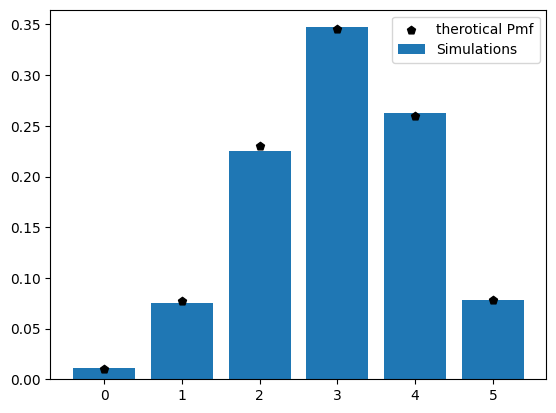

In [ ]:
# Simulation and Empirical Probability
# Simulation generates obervations from an assumed model
# 10,000 groups containing five independent trials p =0.6 each element is a total between 0 and 5

import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
sample=rng.binomial(n=5,p=0.6,size=10000)
k=np.arange(6)
counts=np.bincount(sample,minlength=6)
empirical=counts/len(sample)
print(empirical)
therotical=stats.binom.pmf(k,n=5,p=0.6)
print(therotical)
plt.bar(k,empirical,label='Simulations')
plt.scatter(k,therotical,marker='p',color='black',label='therotical Pmf')
plt.legend()
plt.show()

#14-11-2026
Sampling Techniques and Central Limit Theorem

Population --> Group of interest Sample --> Subset actually examined Population Size --> N Sample size --> n Census --> Collect data from every member

Mean --> mu

In [ ]:

Population = [40,50,60,70,80]
Population_mean = sum(Population)/len(Population)
print(Population_mean)

60.0


In [ ]:


import numpy as np
Population = np.array([40,50,60,70,80])
Population_mean = np.sum(Population)/len(Population)
print(Population_mean)

60.0


In [ ]:
#Sample A --> 40,50   --> Sample Mean A --> 40+50/2 --> 45 --> Error 45 - 60 = -15
#Sample B --> 50,70   --> Sample Mean B --> 50+70/2 --> 60 --> 0
#Sample C --> 70,80   --> Sample Mean C --> 70+80/2 --> 75 -->Error = 75-60 =15
#Sampling Variation -->

#Simple Random Sampling;Systematic Sampling
#Simple Random Sampling
import random
students = list(range(1,1001))
print(students)
print(len(students))
#we want to set a seed value
random.seed(42) #we can take any value but this has given better interpretations
selected_students = random.sample(students,100)
print(selected_students)
print(len(selected_students))


[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 22

In [ ]:


print("First 5 IDs",selected_students[:5])

First 5 IDs [655, 115, 26, 760, 282]


In [ ]:

#Systematic sampling
#Choose a random starting point,then select every kth member..
#if N=1000,n=100 and interval k = N/n = 10
#Starting ID 27 --> 27,37,47,57.....
interval = 10
random.seed(42)
start_index = random.randrange(interval)
print(start_index)
selected_students = students[start_index::interval]
print(selected_students[:])

1
[2, 12, 22, 32, 42, 52, 62, 72, 82, 92, 102, 112, 122, 132, 142, 152, 162, 172, 182, 192, 202, 212, 222, 232, 242, 252, 262, 272, 282, 292, 302, 312, 322, 332, 342, 352, 362, 372, 382, 392, 402, 412, 422, 432, 442, 452, 462, 472, 482, 492, 502, 512, 522, 532, 542, 552, 562, 572, 582, 592, 602, 612, 622, 632, 642, 652, 662, 672, 682, 692, 702, 712, 722, 732, 742, 752, 762, 772, 782, 792, 802, 812, 822, 832, 842, 852, 862, 872, 882, 892, 902, 912, 922, 932, 942, 952, 962, 972, 982, 992]


In [ ]:

print("First Selected ID:",selected_students[0])
print("Selected Count:",len(selected_students))


First Selected ID: 2
Selected Count: 100


Rememember : Periodic patterns in the list can cause problems..If every tenth record belogns to same subgroup (sample)then every tenth selection may misrepresent the popuation.But in above case we have used exact interger interval

In [ ]:
#Stratified Sampling --> Divide the population into meaningful,non-overlapping groups
#called strata..Randomly sample from every stratum..
#Popualtion 1000
#DA   --> 600    --> 60%.    --> 60
#PFS  --> 400    --> 40 %.   --> 40
#Group sample size = (group population / total population) * n
da_students = list(range(1,601))
pfs_students = list(range(601,1001))
random.seed(42)
da_sample = random.sample(da_students,60)
pfs_sample = random.sample(pfs_students,40)
print(da_students)
print(len(da_sample))
print(len(pfs_sample))
print(da_sample[0])
print(pfs_sample[0])
selected_students = da_sample + pfs_sample
print(selected_students)
print(len(selected_students))
#Unequal sampling fractions are also possible..They may require weights(strong criteria)

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 200, 201, 202, 203, 204, 205, 206, 207, 208, 209, 210, 211, 212, 213, 214, 215, 216, 217, 218, 219, 220, 221, 22

In [ ]:

#Cluster Sampling -->Divide the population into natural groups,randomly select some groups
 #for ex --> 4 out of 20 batches randomly and we start surverying student in those
 #4 batches..
 #Stratified --> Every Stratum contribute.   --> represent imp subgroups
 #Cluster --> Some randomly selected clusters. --> data collction practical

 #Convenience Sampling --> It is quick,but conclusions about wider population need care.